In [1]:
# Setup: install the checker and download the public tests (run this cell first)
%pip install -q otter-grader==7.0.0

import os, urllib.request
TESTS_URL = "https://raw.githubusercontent.com/NaiveNeuron/ml_exercises/master/assignment3/tests/"
os.makedirs("tests", exist_ok=True)
for q in ["q1_one_hot", "q2_toy_mlp", "q4_normalization", "q5_mlp", "q7_cnn", "q8_best_model"]:
    path = os.path.join("tests", q + ".py")
    if not os.path.exists(path):
        urllib.request.urlretrieve(TESTS_URL + q + ".py", path)

import otter
grader = otter.Notebook()

Note: you may need to restart the kernel to use updated packages.


# Third assignment: Neural Networks

Welcome to the third practical assignment!

This time you are not going to implement a model from scratch. Instead, you will work with a neural network library called **Keras**. Your task will be to play around with some models: fit them to data, find out why some of them do not learn, and tune their parameters.

Training neural networks takes more computing power (and time) than the previous assignments. In Google Colab, switch to a GPU runtime via *Runtime → Change runtime type → T4 GPU* before you start. The notebook also runs on a CPU, only slower.

### Grading

This tutorial is worth up to **10 points** towards your semester grade (see the [course info](https://compbio.fmph.uniba.sk/vyuka/ml/info.php)). You get the points only if you complete **all exercises** in this notebook (Exercises 1 to 9), including the final challenge at the end (Exercises 8 and 9). Solving only the final challenge earns no points.

Each exercise is marked with a heading such as

<h5 style="color: #1B1BFF">Exercise 1</h5>

Most of them are followed by a `grader.check(...)` cell (for instance, `grader.check("q1_one_hot")` checks Exercise 1). Run it to check your answer against basic tests. Passing these checks does not guarantee the points: when grading, we run additional tests. Exercises 3 and 6 are written answers and Exercise 9 is a short PDF report you submit together with this notebook; we read and grade these by hand.

Some checks evaluate your trained model, so make sure the model variable still holds the model you trained when you run them.

So let's start as usual with some imports and helper functions (we highly recommend you just run this cell and do not modify it).

In [ ]:
# since I prefer working locally and I have AMD GPU (yes I know, I know, but AMD GPU is better on Linux... :( ) and by default 
# Keras uses TensorFlow, so i have to switch the backend to torch, which my venv has the ROCm build of it.
# import os
# os.environ["KERAS_BACKEND"] = "torch"

In [3]:
from matplotlib import pyplot as plt
import numpy as np
import gzip
import os, urllib.request
from sklearn.datasets import make_circles, make_moons, make_blobs

import keras
from keras import layers
from keras.optimizers import SGD, Adam
from keras.utils import to_categorical

# Fix all random seeds (Python, numpy and the Keras backend), so that results are reproducible
keras.utils.set_random_seed(42)

DATA_URL = "https://raw.githubusercontent.com/NaiveNeuron/ml_exercises/master/assignment3/"
for kind in ["train", "test"]:
    for part in ["images-idx3-ubyte.gz", "labels-idx1-ubyte.gz"]:
        name = "{}-{}".format(kind, part)
        if not os.path.exists(name):
            urllib.request.urlretrieve(DATA_URL + name, name)


def get_data(shape='moons', n_samples=200, std=0.1):
    if shape == 'blobs':
        X, y = make_blobs(n_samples, centers=2)
    elif shape == 'circles':
        X, y = make_circles(n_samples, noise=std, factor=0.5)
    elif shape == 'moons':
        X, y = make_moons(n_samples, noise=std)
    else:
        print("Unknown shape! Drawing random sample data.")
        X = np.random.rand(n_samples, 2) * std
        y = np.random.randint(0, 2, n_samples)
    return X, y


def show_data(X, y, title=''):
    plt.figure()
    plt.scatter(X[y == 0, 0], X[y == 0, 1], c='g', label='class 0')
    plt.scatter(X[y == 1, 0], X[y == 1, 1], c='r', label='class 1')
    plt.title(title)
    plt.legend(loc='best')
    plt.show()


def plot_history(history):
    plt.figure()
    plt.plot(history.history['loss'], label='training loss')
    plt.plot(history.history['val_loss'], label='validation loss')
    plt.legend(loc='best')

    plt.figure()
    plt.plot(history.history['accuracy'], label='train accuracy')
    plt.plot(history.history['val_accuracy'], label='validation accuracy')
    plt.legend(loc='best')
    plt.show()


def plot_decision_boundary(model, X, y):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.02),
                         np.arange(y_min, y_max, 0.02))
    Z = np.argmax(model.predict(np.c_[xx.ravel(), yy.ravel()], verbose=0), axis=1)

    plt.figure()
    plt.contourf(xx, yy, Z.reshape(xx.shape), alpha=0.6, cmap=plt.cm.coolwarm)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.coolwarm)
    plt.title('Decision boundary')
    plt.show()


def load_mnist(kind):
    labels_path = './{}-labels-idx1-ubyte.gz'.format(kind)
    images_path = './{}-images-idx3-ubyte.gz'.format(kind)

    with gzip.open(labels_path, 'rb') as lbpath:
        labels = np.frombuffer(lbpath.read(), dtype=np.uint8, offset=8)

    with gzip.open(images_path, 'rb') as imgpath:
        images = np.frombuffer(imgpath.read(), dtype=np.uint8,
                               offset=16).reshape(len(labels), 784)
    return images.reshape(len(images), 28, 28), labels


def visualize_mnist(X, y):
    label_idx = [y == i for i in range(10)]
    ims = np.array([X[label_idx[i]][:10] for i in range(10)])

    classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

    f, axarr = plt.subplots(10, 10, figsize=(12, 12))
    for i in range(10):
        axarr[0][i].set_title(classes[i])
        for j in range(10):
            axarr[i][j].imshow(ims[j][i], 'gray')
            axarr[i][j].axis('off')

    plt.show()

/opt/amdgpu/share/libdrm/amdgpu.ids: No such file or directory
/opt/amdgpu/share/libdrm/amdgpu.ids: No such file or directory
I0000 00:00:1793316089.291817  176763 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793316089.307955  176763 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793316089.921109  176763 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_O

### Part I: Toy data

We will start with what are commonly called *toy datasets*. They can be generated by the `get_data()` function, which takes one of the following values as its first parameter:

* `'moons'`
* `'circles'`
* `'blobs'`
* anything else (this results in an unknown shape and random data)

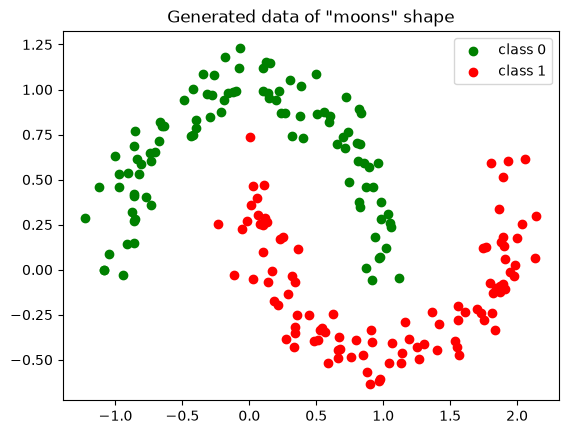

Shape of data - X: (200, 2) | y: (200,)


In [4]:
X, y = get_data('moons')
show_data(X, y, 'Generated data of "moons" shape')

print("Shape of data - X: {} | y: {}".format(X.shape, y.shape))

Keras (https://keras.io/) is a high-level neural networks API, written in Python. It runs on top of one of the lower-level, 'research like' neural network libraries, such as [JAX](https://github.com/jax-ml/jax), [TensorFlow](https://github.com/tensorflow/tensorflow) or [PyTorch](https://pytorch.org/).

All of these libraries operate on the same principle. They build **computational graphs** which are then used to compute gradients using the backpropagation algorithm (if you are interested you can read more about computational graphs and backpropagation here: http://cs231n.github.io/optimization-2/).

The **Keras** library was developed as a quick prototyping tool. It allows you to specify your models and their parts as you would describe them on paper. It supports most of today's standard neural network building blocks as well as most of the deep learning models (Convolutional Neural Networks, Recurrent Neural Networks, even [Transformers](https://keras.io/examples/nlp/text_classification_with_transformer/)...).

The core Keras data structure is a model. The simplest available model is `keras.Sequential()`, which is just a linear stack of layers (you can build more complex models through the Keras functional API). We pass it the list of layers, starting with `keras.Input(...)`, which tells Keras the shape of a single input example, so that it can prepare its weights.

The simplest model we can build is called a **Multi Layered Perceptron (MLP)**. This model contains just fully-connected layers. In Keras these are called **Dense** layers. The first parameter of a layer is the number of neurons it has. We can then specify the **activation function** to be applied on its outputs by setting the `activation` parameter.

Our targets are now in a one dimensional array with values 0 and 1. This would be fine if our model output just one probability value (we could for instance use one sigmoid neuron as the output layer). Our model, however, will have two output neurons with the softmax activation, so that we can interpret their values as the probability that the example belongs to each of the two classes. We therefore need to transform our targets into a **categorical variable** by adding what are called *dummy variables*.

Each target then consists of 2 dimensions. The dimension that represents the *true* class is set to **one**. Every other dimension is set to **zero**. This process is also called **one-hot encoding**.

<h5 style="color: #1B1BFF">Exercise 1</h5>

Without using any library function, create the matrix `y_onehot` of shape `(200, 2)`, which contains the one-hot encoding of `y`.

*Hint:* indexing an identity matrix (`np.eye`) by `y` is one way of doing it.

Keras provides a handy function `to_categorical` which does the same thing; we will use it from now on. Feel free to compare your result with it.

In [5]:
identity = np.eye(2, 2)
#print(identity)
y_onehot = identity[y]

print(y[:10])
print(y_onehot[:10])
#print(y_onehot.shape)
#print(np.array_equal(y_onehot, to_categorical(y)))

[0 0 0 1 1 1 0 1 1 0]
[[1. 0.]
 [1. 0.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [0. 1.]
 [1. 0.]
 [0. 1.]
 [0. 1.]
 [1. 0.]]


In [6]:
grader.check("q1_one_hot")

q1_one_hot results: All test cases passed!

We prepared a simple example model that consists of two layers. The first one has 6 neurons and uses the `tanh` activation function. The second (output) layer has two neurons (one for each class) and the softmax activation function.

After you specify your model, you need to compile it, so that Keras can prepare its computational graph. Here you specify the **loss** the model is supposed to optimize, the **optimizer**, which is the algorithm used to optimize it (in our case standard stochastic gradient descent, SGD), and a list of **metrics** to be computed during training.

Finally, we train the model using the `fit()` function. Keras also prepares the training/validation split for us via the `validation_split` parameter. It takes float values from 0.0 to 1.0, which represent the fraction of the training data used for validation. In our case it is 10%, meaning we set `validation_split=0.1`.

`fit()` returns a `history` object. It contains the values of the loss and the metrics throughout the training. It is often very useful to plot these values, so that we can better understand what our model is doing (is the loss going down, are we overfitting/underfitting/...).

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6556 - loss: 0.6521 - val_accuracy: 0.7000 - val_loss: 0.6032
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8611 - loss: 0.5292 - val_accuracy: 0.8000 - val_loss: 0.5242
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8556 - loss: 0.4064 - val_accuracy: 0.7500 - val_loss: 0.4787
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8556 - loss: 0.3177 - val_accuracy: 0.8000 - val_loss: 0.4915
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8611 - loss: 0.2844 - val_accuracy: 0.8000 - val_loss: 0.5308
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8722 - loss: 0.2693 - val_accuracy: 0.7500 - val_loss: 0.5137
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8778 - loss: 0.2545 - val_accuracy: 0.7500 - val_loss: 0.5043
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8722 - loss: 0.2425 - val_accuracy: 0.7500 - val_loss: 0.4960


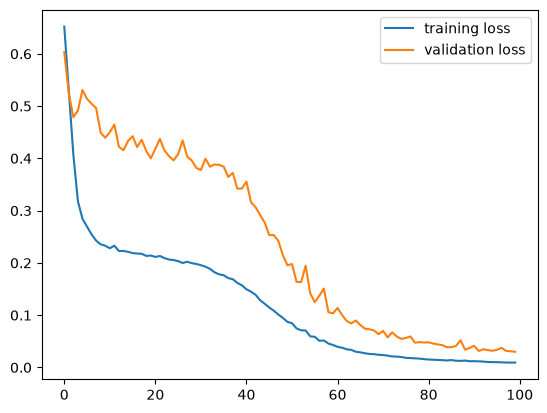

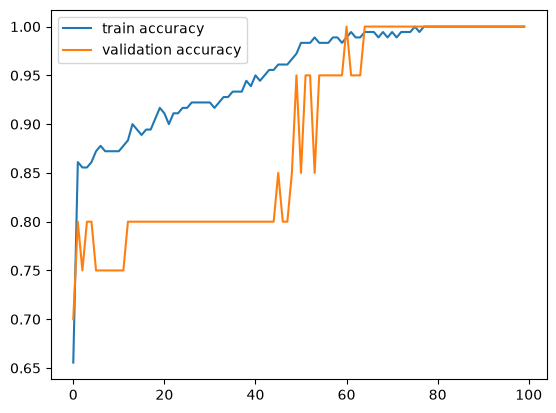

In [7]:
toy_mlp = keras.Sequential([
    keras.Input(shape=(2,)),
    layers.Dense(6, activation='relu'), # use relu activation function instead of tanh
    layers.Dense(16, activation='relu'), # add another layer to increase model capacity
    layers.Dense(2, activation='softmax'),
])

# lr=0.4 is too high, also use Adam instead of SGD with lr=0.01
toy_mlp.compile(loss='categorical_crossentropy', optimizer=Adam(learning_rate=0.01), metrics=['accuracy']) 

# increase the number of epoch to 100
history = toy_mlp.fit(X, to_categorical(y), epochs=100, validation_split=0.1, verbose=True)
plot_history(history)

Keras also provides a handy function that allows us to evaluate our models on the metrics that we previously specified:

In [8]:
score = toy_mlp.evaluate(X, to_categorical(y))
print("\n\nloss: {} | train acc: {}".format(score[0], score[1]))

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 1.0000 - loss: 0.0108


loss: 0.010797024704515934 | train acc: 1.0


We can also plot the points that our model misclassified.

Although this is just a toy example, error analysis like this is the key to getting intuition about both the problem and the model at hand. Unless you for some reason cannot do it, it is highly recommended in any Machine Learning project you end up doing.

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 805us/step


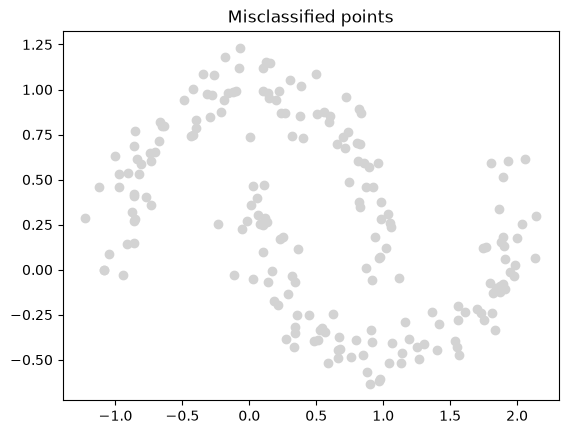

In [9]:
predictions = np.argmax(toy_mlp.predict(X), axis=1)

plt.figure()
plt.scatter(X[:, 0], X[:, 1], c='lightgray')
plt.scatter(X[predictions != y, 0], X[predictions != y, 1], c=y[predictions != y], cmap=plt.cm.coolwarm)
plt.title('Misclassified points')
plt.show()

For a simple two dimensional problem like this we can also plot the *decision boundary*: the line through the input space where the model switches from one class to the other.

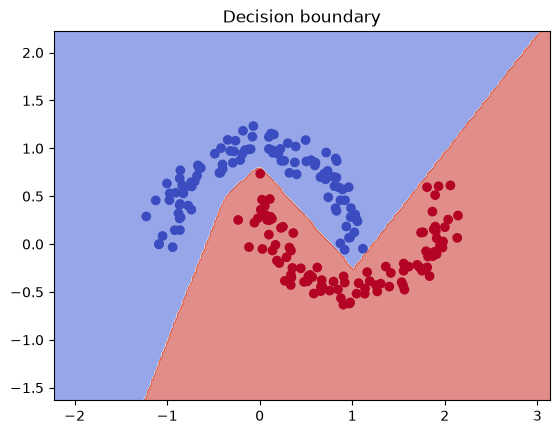

In [10]:
plot_decision_boundary(toy_mlp, X, y)

<h5 style="color: #1B1BFF">Exercise 2</h5>

The model above does not separate the two moons very well. Change the cell where `toy_mlp` is defined and trained (the number of neurons and layers, the activation functions, the learning rate, the optimizer or the number of epochs; check the docs at https://keras.io/api/), so that `toy_mlp` reaches an accuracy of at least **97%** on `X`. Then rerun the cells above to see how the decision boundary changed.

In [11]:
grader.check("q2_toy_mlp")

q2_toy_mlp results: All test cases passed!

<!-- BEGIN QUESTION -->

<h5 style="color: #1B1BFF">Exercise 3</h5>

What effect does changing the number of neurons, or adding/removing layers, have on the decision boundary and the resulting classification? Try at least one other dataset as well (for instance `X, y = get_data('circles')`).

Write your answer into the `q3_answer` string below. A few sentences are enough.

In [12]:
# Write your answer as plain text between the triple quotes.
q3_answer = """
On the circles dataset, for example when changing the number of neurons in the first layer to 2 (layers.Dense(2, activation='relu')), the decision boundary is just a single line
and accuracy drops to 0.64. Increasing the number of neurons just by one helps the accuracy to jump to 0.97 and we can see the decision boundary is no longer a line, but some quadrilateral.

When changing the number of neurons back to 2 and adding another layer with 2 neurons, the accuracy is 0.78 and the decision boundary is similar triangle now.
Interestingly, when I added another 4 layers with 2 neurons, so having 6 layers.Dense(2, activation='relu') in total, the accuracy drops to around 0.5 (so basically just guessing) and 
the decision boundary is the whole plane, so the model just predicts the one class.

Similar behavior is seen in the moons dataset also.
"""

<!-- END QUESTION -->

----------------------------------------------------------------------------------------------------------

### Part II: Fashion-MNIST

In the second part of this assignment we will work with the **Fashion-MNIST dataset**. Note that both its name and its content are a "play" on the (to some extent) overused "default" dataset of Machine Learning, the [MNIST dataset](https://en.wikipedia.org/wiki/MNIST_database).

The dataset consists of 60 000 training examples and 10 000 test examples. Each of them is a grayscale picture of 28x28 pixels. There are 10 classes:

* T-shirt/top
* Trouser
* Pullover
* Dress
* Coat
* Sandal
* Shirt
* Sneaker
* Bag
* Ankle boot

We already loaded the data for you.

In [13]:
X_train, y_train = load_mnist('train')
print("Train data shape: {} | labels: {}".format(X_train.shape, y_train.shape))

X_test, y_test = load_mnist('test')
print("Test data shape: {} | labels: {}".format(X_test.shape, y_test.shape))

Train data shape: (60000, 28, 28) | labels: (60000,)
Test data shape: (10000, 28, 28) | labels: (10000,)


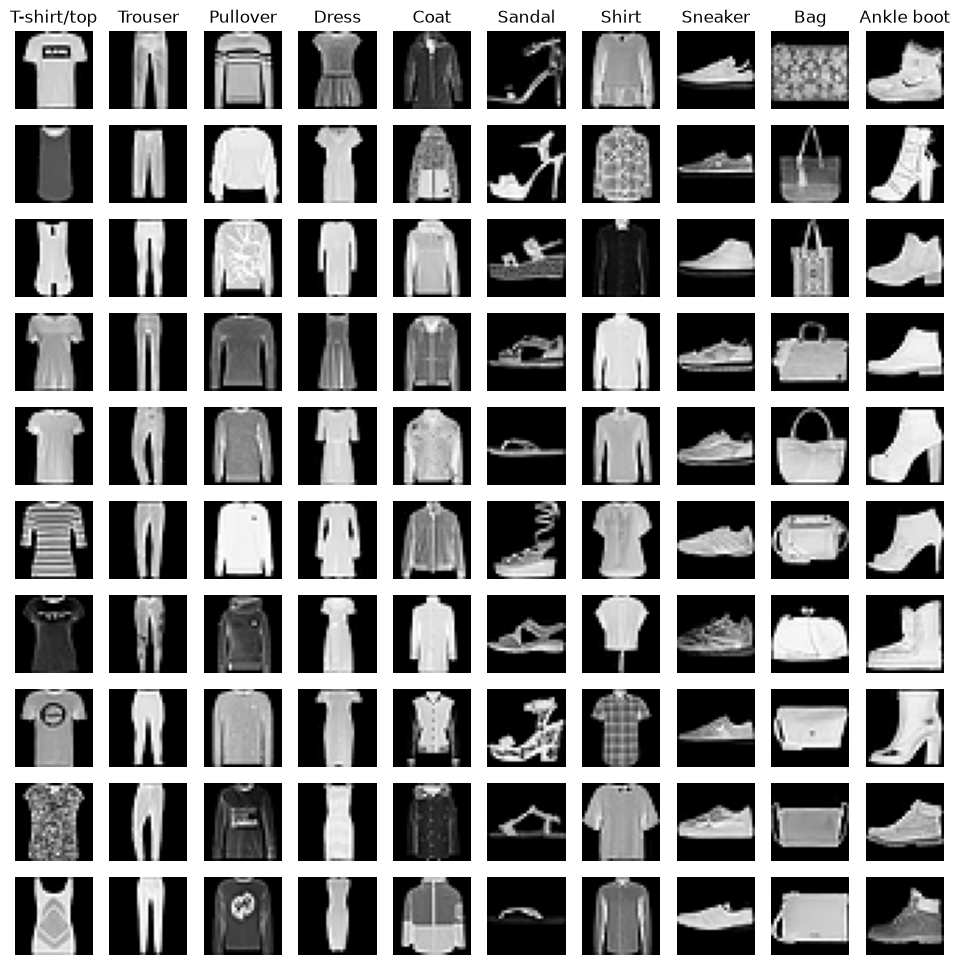

In [14]:
visualize_mnist(X_train, y_train)

Just as before, let us start with a simple *MLP*. Since our data has the shape of a 28x28 pixel image, we first need to turn each example into a single vector, so that it can be fed into the model.

In [15]:
X_train = X_train.reshape(-1, 28 * 28)
X_test = X_test.reshape(-1, 28 * 28)
print("New train data shape: {} | test data: {}".format(X_train.shape, X_test.shape))

New train data shape: (60000, 784) | test data: (10000, 784)


<h5 style="color: #1B1BFF">Exercise 4</h5>

Neural networks are in general very sensitive to the scale of their inputs, so it is almost always a good idea to normalize your data. With images it is usually enough to divide every value by 255, the highest value a pixel can have.

Normalize `X_train` and `X_test`, so that all their values lie between 0 and 1. Keep their shapes.

In [16]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Train data range: [{}, {}]".format(X_train.min(), X_train.max()))

Train data range: [0.0, 1.0]


In [17]:
grader.check("q4_normalization")

q4_normalization results: All test cases passed!

In the cell below there is a simple MLP with 3 layers. The first two, with 100 neurons each, use the `tanh` activation function. At the end there is again a softmax layer with 10 neurons (one for each class).

Here we optimize the **categorical cross-entropy** with a new optimizer called **Adam** (https://arxiv.org/pdf/1412.6980.pdf, https://machinelearningmastery.com/adam-optimization-algorithm-for-deep-learning/).

<h5 style="color: #1B1BFF">Exercise 5</h5>

Run the cell below and look at the plots: the model barely learns anything, even on normalized data. Find out why and fix it, so that `mlp` reaches a **test accuracy of at least 85%**.

Make your decisions based on the validation accuracy, not the test accuracy. As you may recall, it is good practice to compute the test score only once, when you have already chosen your *best* model.

Epoch 1/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8264 - loss: 0.4800 - val_accuracy: 0.8602 - val_loss: 0.3870
Epoch 2/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8646 - loss: 0.3688 - val_accuracy: 0.8677 - val_loss: 0.3557
Epoch 3/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8759 - loss: 0.3348 - val_accuracy: 0.8695 - val_loss: 0.3743
Epoch 4/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8853 - loss: 0.3110 - val_accuracy: 0.8755 - val_loss: 0.3329
Epoch 5/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.8889 - loss: 0.2967 - val_accuracy: 0.8708 - val_loss: 0.3523
Epoch 6/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8950 - loss: 0.2815 - val_accuracy: 0.8748 - val_loss: 0.3310
Epoch 7/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.8997 - loss: 0.2684 - val_accuracy: 0.8843 - val_loss: 0.3278
Epoch 8/30
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9032 - loss: 0.2578 - 

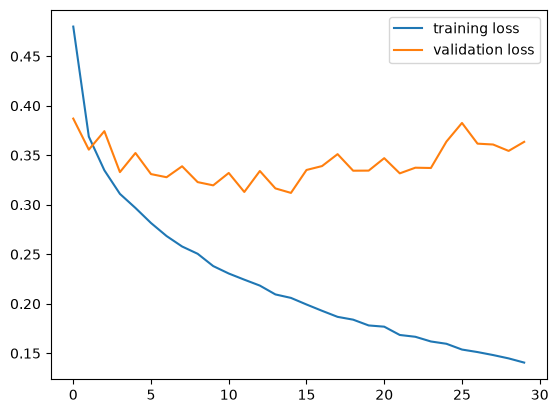

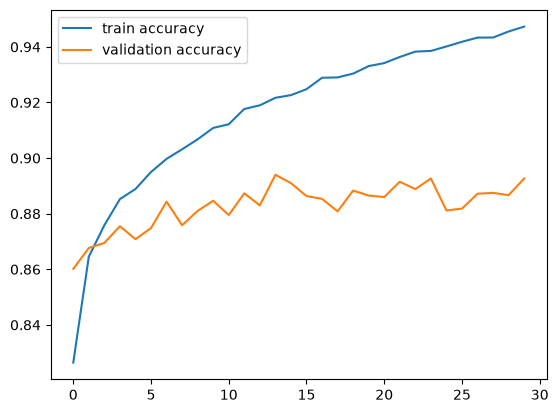

In [18]:
mlp = keras.Sequential([
    keras.Input(shape=(28 * 28,)),
    layers.Dense(100, activation='tanh'),
    layers.Dense(100, activation='tanh'),
    layers.Dense(10, activation='softmax'),
])

mlp.compile(loss='categorical_crossentropy', optimizer=Adam(0.001), metrics=['accuracy'])

history = mlp.fit(X_train, to_categorical(y_train), epochs=30, validation_split=0.1, verbose=True)
plot_history(history)

In [19]:
train_score = mlp.evaluate(X_train, to_categorical(y_train))
print("\n\ntrain loss: {} | train acc: {}\n".format(train_score[0], train_score[1]))

test_score = mlp.evaluate(X_test, to_categorical(y_test))
print("\n\ntest loss: {} | test acc: {}".format(test_score[0], test_score[1]))

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 3s 1ms/step - accuracy: 0.9466 - loss: 0.1523


train loss: 0.1523309051990509 | train acc: 0.946566641330719

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8840 - loss: 0.3878


test loss: 0.3877999186515808 | test acc: 0.8840000033378601


In [20]:
grader.check("q5_mlp")

q5_mlp results: All test cases passed!

<!-- BEGIN QUESTION -->

<h5 style="color: #1B1BFF">Exercise 6</h5>

What was wrong with the original MLP, and why did your change fix it? What did the loss and accuracy curves look like before and after?

Write your answer into the `q6_answer` string below. A few sentences are enough.

In [21]:
# Write your answer as plain text between the triple quotes.
q6_answer = """
The problem was the size of the learning rate of Adam optimizer, 0.04, which is 40x the default of 0.001. Since the Adam optimizer takes steps mostly based on the value of learning rate,
having the value of learning rate that high causes the model to overshoot the weight updates, which can be seen in the loss and accuracy graphs, where the loss does not decrease and accuracy 
stays around 0.2. After fixing the learning rate, the loss drops smoothly (at least the training loss, we can see on the val loss curve that the model is starting to overfit)
and the test accuracy reaches around 0.88.
"""

<!-- END QUESTION -->

### Part III: Convolutional Neural Network

Now we are going to use a **Convolutional Neural Network** on our data. Since convolutions can directly process 2D data (which is how our images are represented), we again reshape our data, this time to 28x28x1. The last number is the number of channels our images have. Since we only have grayscale images, it is 1. If we had full RGB images, it would be 3.

In [22]:
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

print("New train data shape: {} | test data: {}".format(X_train.shape, X_test.shape))

New train data shape: (60000, 28, 28, 1) | test data: (10000, 28, 28, 1)


A convolutional neural network is again just another `Sequential` model. Convolutional layers are added as `layers.Conv2D(filters, kernel_size, activation=...)`, where the first parameter is the number of filters and the second is their size.

*For more information on all of these concepts, please consult [Stanford's CS231n lecture notes](http://cs231n.github.io/convolutional-networks/) on the topic. Despite being a bit dated, they are still an excellent resource.*

This time we are going to run our optimizer on **batches** of data: we take a batch of 512 examples, compute the loss on all of them and only then backpropagate. This makes training significantly faster, since we update the weights once per batch rather than after every single example.

<h5 style="color: #1B1BFF">Exercise 7</h5>

Build the model `cnn` with the following architecture:

1. a 2D convolutional layer with 32 filters of size 3x3 and the `relu` activation,
2. a 2D convolutional layer with 64 filters of size 3x3 and the `relu` activation,
3. a max pooling layer (`layers.MaxPooling2D`) of size 2x2, which halves the width and height of the output of the second convolutional layer,
4. a `layers.Flatten()` layer, which turns its input into a single vector,
5. a fully-connected output layer with 10 neurons (one for each class) and the softmax activation function.

Then train it with the cell below. It should reach a **test accuracy of at least 88%**.

Epoch 1/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 50ms/step - accuracy: 0.7655 - loss: 0.6872 - val_accuracy: 0.8458 - val_loss: 0.4423
Epoch 2/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.8615 - loss: 0.3981 - val_accuracy: 0.8673 - val_loss: 0.3745
Epoch 3/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.8789 - loss: 0.3470 - val_accuracy: 0.8847 - val_loss: 0.3333
Epoch 4/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.8899 - loss: 0.3128 - val_accuracy: 0.8877 - val_loss: 0.3166
Epoch 5/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.8991 - loss: 0.2861 - val_accuracy: 0.8943 - val_loss: 0.2960
Epoch 6/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.9050 - loss: 0.2704 - val_accuracy: 0.9023 - val_loss: 0.2812
Epoch 7/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.9098 - loss: 0.2547 - val_accuracy: 0.9018 - val_loss: 0.2735
Epoch 8/10
106/106 ━━━━━━━━━━━━━━━━━━━━ 5s 48ms/step - accuracy: 0.9149 - loss: 0.2406 - val_accu

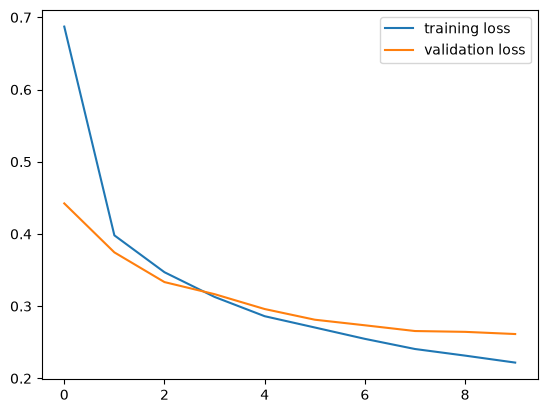

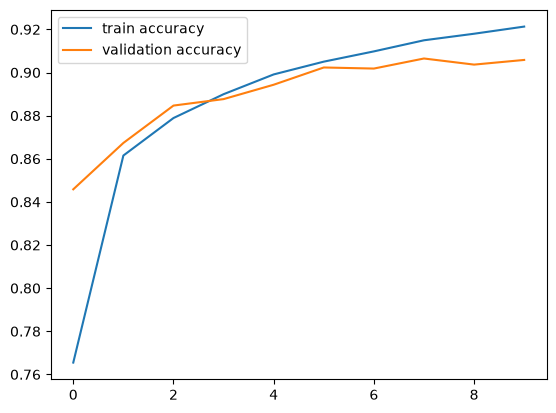

In [23]:
cnn = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, activation='relu'),
    layers.Conv2D(64, 3, activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(10, activation='softmax'),
])

cnn.compile(loss='categorical_crossentropy', optimizer=Adam(0.001), metrics=['accuracy'])

history = cnn.fit(X_train, to_categorical(y_train), epochs=10, batch_size=512,
                  validation_split=0.1, verbose=True)
plot_history(history)

In [24]:
train_score = cnn.evaluate(X_train, to_categorical(y_train))
print("\n\ntrain loss: {} | train acc: {}\n".format(train_score[0], train_score[1]))

test_score = cnn.evaluate(X_test, to_categorical(y_test))
print("\n\ntest loss: {} | test acc: {}".format(test_score[0], test_score[1]))

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9227 - loss: 0.2161


train loss: 0.21611140668392181 | train acc: 0.9226999878883362

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8998 - loss: 0.2782


test loss: 0.2781970798969269 | test acc: 0.8998000025749207


In [25]:
grader.check("q7_cnn")

q7_cnn results: All test cases passed!

----------------------------------------------------------------------------------------------------------

### Part IV: Final challenge

Now it is your turn to build the best Fashion-MNIST model you can.

<h5 style="color: #1B1BFF">Exercise 8</h5>

Build, train and store in `best_model` a model that reaches a **test accuracy of at least 91%**. You can take the CNN above as a starting point and try deeper networks, more filters, dropout, batch normalization, data augmentation, learning rate schedules, more epochs, ...

The rules:

* Your model needs to be neural-network based and implemented by you. If you use an architecture that has already been described elsewhere, reference it in your report (Exercise 9).
* Your model needs to be trained on *just* the **training** data. Choose your model and its parameters using validation data, not the test data.
* Your model needs to take the images in the same shape as `X_test` above, that is `(28, 28, 1)`, normalized to values between 0 and 1.
* **Your accuracy needs to be reproducible!** We need to get the same result when we run your notebook. Keep the `keras.utils.set_random_seed(...)` call in the cell below.

Epoch 1/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 12s 109ms/step - accuracy: 0.7068 - loss: 0.8102 - val_accuracy: 0.8372 - val_loss: 0.4409
Epoch 2/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.8482 - loss: 0.4232 - val_accuracy: 0.8670 - val_loss: 0.3522
Epoch 3/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.8709 - loss: 0.3610 - val_accuracy: 0.8832 - val_loss: 0.3185
Epoch 4/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.8833 - loss: 0.3262 - val_accuracy: 0.8945 - val_loss: 0.2913
Epoch 5/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.8924 - loss: 0.2994 - val_accuracy: 0.8970 - val_loss: 0.2765
Epoch 6/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.9021 - loss: 0.2753 - val_accuracy: 0.9082 - val_loss: 0.2517
Epoch 7/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.9056 - loss: 0.2600 - val_accuracy: 0.9073 - val_loss: 0.2540
Epoch 8/20
106/106 ━━━━━━━━━━━━━━━━━━━━ 11s 108ms/step - accuracy: 0.9113 - loss: 0

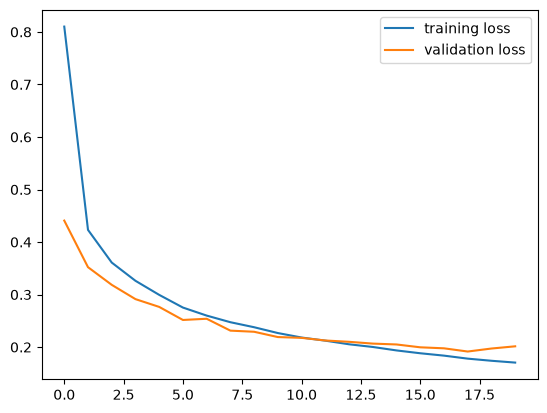

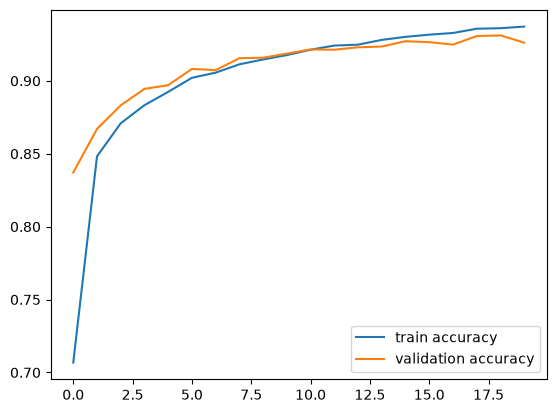

In [26]:
keras.utils.set_random_seed(42)

best_model = keras.Sequential([
    keras.Input(shape=(28, 28, 1)),

    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.Conv2D(32, 3, activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.Conv2D(64, 3, activation='relu', padding='same'),
    layers.MaxPooling2D((2, 2)),

    layers.Dropout(0.5),
    layers.Flatten(),
    layers.Dense(10, activation='softmax'),
])


best_model.compile(loss='categorical_crossentropy', optimizer=Adam(0.001), metrics=['accuracy'])

history = best_model.fit(X_train, to_categorical(y_train), epochs=20, batch_size=512,
                  validation_split=0.1, verbose=True)
plot_history(history)

In [27]:
test_score = best_model.evaluate(X_test, to_categorical(y_test))
print("\n\ntest loss: {} | test acc: {}".format(test_score[0], test_score[1]))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9232 - loss: 0.2127


test loss: 0.21265490353107452 | test acc: 0.9232000112533569


In [28]:
grader.check("q8_best_model")

q8_best_model results: All test cases passed!

<h5 style="color: #1B1BFF">Exercise 9</h5>

Write a short report (**at most 2 pages**, preferably in the [Lecture Notes in Computer Science](https://github.com/latextemplates/LNCS) format) describing your approach and your results: what your final model looks like, what you tried along the way, what helped and what did not, and what validation and test accuracy you reached. Reference any architecture or idea you took from elsewhere.

Submit the report as a **PDF** together with this notebook.

*If you need any help with this assignment, please feel free to contact the course TAs, whose contact info can be found on the [course website](http://compbio.fmph.uniba.sk/vyuka/ml/).*


**Thanks for reading this far!**